# Automatic differentiation: how a PINN builds its residual

A PINN differentiates a network **twice over**: once with respect to its
*inputs* $(x,t)$ to build the PDE residual, and once with respect to its
*parameters* $\boldsymbol{\theta}$ to train. Both are done by the same
engine, automatic differentiation (AD). This notebook opens that engine up
before the other PINN notebooks hide it behind a helper.

1. Three ways to differentiate: analytic, finite differences, AD.
2. One neuron by hand — the chain rule that AD automates.
3. $u_t$, $u_x$, $u_{xx}$ of a network and the heat residual.
4. Input derivatives versus parameter gradients.
5. `requires_grad`, `grad_outputs`, `create_graph` — what each one does.
6. Why ReLU breaks a second-order residual.
7. Vector outputs and the Laplacian — two common bugs.
8. Exercise: write a residual yourself, then meet the helper.

Every derivative is checked against an independent reference. Floating-point
precision (float32 vs float64) is covered in Module 15 (`dlp_precision`); here
everything runs in float64.

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
X0 = 0.7                 # point where the scalar test function is differentiated
H_MIN, H_MAX, N_H = 1e-12, 1e-1, 45   # finite-difference step sweep
ALPHA = 0.1              # heat diffusivity in the residual examples
N_COL = 256              # collocation points for residual / gradient checks
WIDTH = 20               # hidden width of the small test networks
D_LAP = 3                # input dimension of the Laplacian example
RELU_STEPS, RELU_WIDTH = 1500, 32   # heat PINNs trained with tanh and with ReLU (section 6)
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, X0=0.7, H_MIN=1e-12, H_MAX=1e-1, N_H=45, ALPHA=0.1,
                N_COL=256, WIDTH=20, D_LAP=3, RELU_STEPS=1500, RELU_WIDTH=32)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils import save_dual, fg

torch.set_default_dtype(torch.float64)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
pc.set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## 1. Three ways to differentiate

Take a smooth test function with known derivatives,

$$f(x)=e^{-x}\sin 3x,\qquad
  f'(x)=e^{-x}(3\cos 3x-\sin 3x),\qquad
  f''(x)=-e^{-x}(6\cos 3x+8\sin 3x).$$

**Centered finite differences** approximate the derivative from nearby
function values. They have two error sources that pull in opposite
directions: Taylor *truncation* (shrinks with the step $h$) and floating-point
*rounding* in the numerator (grows as $h$ shrinks, because nearly equal
numbers are subtracted and then divided by a small $h$ or $h^2$).

**AD** applies the chain rule to the exact operations the code performs. It
has no step size, so no truncation error; what remains is the ordinary
rounding of each elementary operation.

In [3]:
def f_np(x):   return np.exp(-x) * np.sin(3 * x)
def df_np(x):  return np.exp(-x) * (3 * np.cos(3 * x) - np.sin(3 * x))
def d2f_np(x): return -np.exp(-x) * (6 * np.cos(3 * x) + 8 * np.sin(3 * x))

hs = np.logspace(np.log10(H_MIN), np.log10(H_MAX), N_H)
err_fd1 = np.abs((f_np(X0 + hs) - f_np(X0 - hs)) / (2 * hs) - df_np(X0))
err_fd2 = np.abs((f_np(X0 + hs) - 2 * f_np(X0) + f_np(X0 - hs)) / hs**2 - d2f_np(X0))

# AD: raw torch.autograd.grad, nested once for the second derivative
x = torch.tensor([X0], requires_grad=True)
f = torch.exp(-x) * torch.sin(3 * x)
(f_x,) = torch.autograd.grad(f, x, create_graph=True)   # keep a graph of f_x ...
(f_xx,) = torch.autograd.grad(f_x, x)                    # ... so it can be differentiated
err_ad1 = abs(f_x.item() - df_np(X0))
err_ad2 = abs(f_xx.item() - d2f_np(X0))

i1, i2 = err_fd1.argmin(), err_fd2.argmin()
print(f"first derivative : best FD error {err_fd1[i1]:.1e} at h={hs[i1]:.0e};  AD error {err_ad1:.1e}")
print(f"second derivative: best FD error {err_fd2[i2]:.1e} at h={hs[i2]:.0e};  AD error {err_ad2:.1e}")

first derivative : best FD error 1.6e-11 at h=2e-06;  AD error 0.0e+00
second derivative: best FD error 1.3e-08 at h=1e-04;  AD error 4.4e-16


**Why the error curve is V-shaped.** Taylor expansion gives the two error
sources explicitly ($\varepsilon\approx1.1\times10^{-16}$ is the unit
roundoff of float64):

$$E_1(h)\approx\underbrace{\tfrac{h^2}{6}\,|f'''|}_{\text{truncation}}
   +\underbrace{\tfrac{\varepsilon}{h}\,|f|}_{\text{rounding}},\qquad
  E_2(h)\approx\tfrac{h^2}{12}\,|f''''|+\tfrac{4\varepsilon}{h^2}\,|f|.$$

Truncation is a power law in $h$, so on log–log axes it is a straight line of
slope $2$. Rounding grows as $h$ shrinks because $f(x+h)-f(x-h)$ subtracts two
nearly equal numbers (losing digits) and the result is divided by $h$ (or
$h^2$): a straight line of slope $-1$ (or $-2$). Refining $h$ therefore helps
only until the two lines cross, at $h^\ast=(3\varepsilon|f|/|f'''|)^{1/3}$ for
$f'$ and $h^\ast=(48\varepsilon|f|/|f''''|)^{1/4}$ for $f''$; beyond that point
every further refinement makes the answer *worse*. The jagged left branch is
rounding noise: its size, not its exact value, is predictable.

predicted best h: f' 2.1e-06 (measured 2e-06);  f'' 1.2e-04 (measured 1e-04)


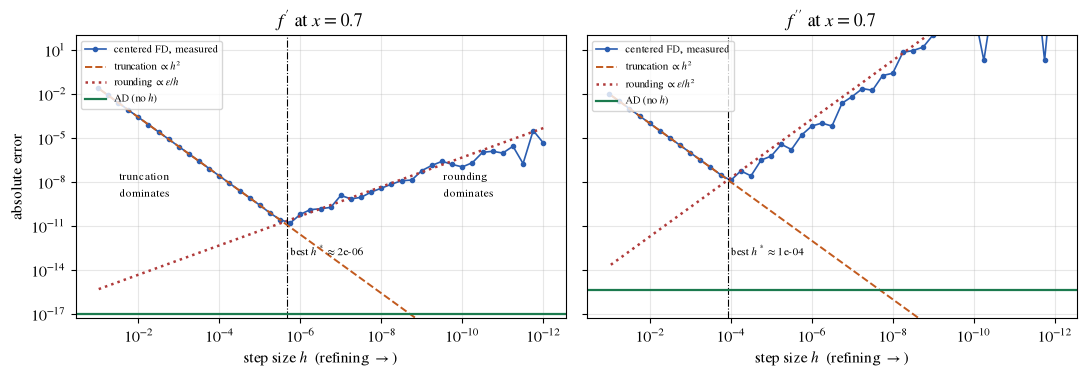

In [4]:
EPS = np.finfo(float).eps / 2          # unit roundoff of float64
def fn_np(x, n):                       # n-th derivative of exp(-x) sin(3x)
    return np.imag((-1 + 3j)**n * np.exp((-1 + 3j) * x))
f0, f3, f4 = abs(fn_np(X0, 0)), abs(fn_np(X0, 3)), abs(fn_np(X0, 4))
trunc1, round1 = hs**2 / 6 * f3, EPS / hs * f0
trunc2, round2 = hs**2 / 12 * f4, 4 * EPS / hs**2 * f0
hstar1 = (3 * EPS * f0 / f3)**(1 / 3)
hstar2 = (48 * EPS * f0 / f4)**(1 / 4)
print(f"predicted best h: f' {hstar1:.1e} (measured {hs[i1]:.0e});  f'' {hstar2:.1e} (measured {hs[i2]:.0e})")


def plot_ad_fd_error():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
    floor = 1e-17   # an error of exactly 0 is drawn at this floor
    panels = [(axes[0], err_fd1, trunc1, round1, hstar1, err_ad1, "f'", r'$\propto h^2$', r'$\propto \varepsilon/h$'),
              (axes[1], err_fd2, trunc2, round2, hstar2, err_ad2, "f''", r'$\propto h^2$', r'$\propto \varepsilon/h^2$')]
    for ax, err, tr, ro, hst, ead, name, ltr, lro in panels:
        ax.loglog(hs, err, 'o-', ms=3, lw=1.2, color='C0', label='centered FD, measured')
        ax.loglog(hs, tr, '--', color='C1', lw=1.4, label=f'truncation {ltr}')
        ax.loglog(hs, ro, ':', color='C3', lw=1.8, label=f'rounding {lro}')
        ax.axvline(hst, color=fg(), lw=0.8, ls='-.')
        ax.text(hst, 1e-13, f' best $h^*\\approx${hst:.0e}', fontsize=8, color=fg())
        ax.axhline(max(ead, floor), color='C2', lw=1.6, label='AD (no $h$)')
        ax.invert_xaxis()   # left to right = refining the step
        ax.set(xlabel=r'step size $h$  (refining $\rightarrow$)', title=f'${name}$ at $x={X0}$',
               ylim=(5e-18, 1e2))
        ax.legend(loc='upper left', fontsize=7.5)
    axes[0].set_ylabel('absolute error')
    axes[0].annotate('truncation\ndominates', xy=(3e-2, 1e-9), color=fg(), fontsize=8)
    axes[0].annotate('rounding\ndominates', xy=(3e-10, 1e-9), color=fg(), fontsize=8)
    plt.tight_layout()

save_dual(plot_ad_fd_error, 'pinn_ad_fd_error', FIG)
plt.show()

In [5]:
assert err_ad1 < 1e-14 and err_ad2 < 1e-13, "AD agrees with the analytic derivative to rounding"
assert err_fd1.min() > 100 * max(err_ad1, 1e-16), "FD at its best h is still far less accurate than AD"
assert err_fd2.min() > 1e-10, "second-derivative FD cannot beat ~sqrt(machine eps)"
assert err_fd1[0] > 1e-6 and err_fd1[-1] > 1e-4, "both ends of the sweep are bad: the V shape"
assert 0.1 < hs[i1] / hstar1 < 10 and 0.1 < hs[i2] / hstar2 < 10, "measured best h matches the error model"

The V shape is the finite-difference dilemma. The best achievable error is
about $\varepsilon^{2/3}$ for $f'$ and $\varepsilon^{1/2}$ for $f''$
($\varepsilon\approx2\times10^{-16}$), and it is reached only at a step size
you would have to know in advance. AD sits at rounding level with nothing to
tune. "Exact" therefore means *exact up to floating-point rounding*, not
infinitely precise.

## 2. One neuron, by hand

AD is the chain rule, applied mechanically to a **computation graph**. For a
one-neuron network (the $m=1$ case of the chapter's worked example)

$$u = v\tanh(wx+b)+c$$

the graph is $x \to z=wx+b \to s=\tanh z \to u=vs+c$. (Here $s$ is the
neuron's hidden value; it has nothing to do with the finite-difference step
$h$ above.) Each edge has a *local* derivative, and the derivative of the
output is their product:

$$\frac{du}{dx} = \underbrace{\frac{du}{ds}}_{v}\;
   \underbrace{\frac{ds}{dz}}_{1-s^2}\;
   \underbrace{\frac{dz}{dx}}_{w},
  \qquad
  \frac{d^2u}{dx^2} = \frac{d}{dx}\Big[v\,w\,(1-s^2)\Big] = -2\,v\,w^2\,s\,(1-s^2).$$

Reverse-mode AD records the forward values, then walks the graph backwards
multiplying local derivatives — exactly this product.

In [6]:
v, w, b, c = 1.5, 2.0, -0.5, 0.3
xn = torch.tensor([0.4], requires_grad=True)
z = w * xn + b
s_ = torch.tanh(z)
u = v * s_ + c

rows = [('x', xn.item(), '—'), ('z = w x + b', z.item(), f'dz/dx = w = {w}'),
        ('s = tanh z', s_.item(), f'ds/dz = 1 - s^2 = {1 - s_.item()**2:.6f}'),
        ('u = v s + c', u.item(), f'du/ds = v = {v}')]
print(f"{'node':<14}{'forward value':>15}   local derivative")
for name, val, loc in rows:
    print(f"{name:<14}{val:>15.6f}   {loc}")

du_hand = v * (1 - s_.item()**2) * w
d2u_hand = -2 * v * w**2 * s_.item() * (1 - s_.item()**2)
(u_x,) = torch.autograd.grad(u, xn, create_graph=True)
(u_xx,) = torch.autograd.grad(u_x, xn)
print(f"\ndu/dx   by hand {du_hand:.12f}   by AD {u_x.item():.12f}")
print(f"d2u/dx2 by hand {d2u_hand:.12f}   by AD {u_xx.item():.12f}")
assert abs(du_hand - u_x.item()) < 1e-14 and abs(d2u_hand - u_xx.item()) < 1e-14

node            forward value   local derivative
x                    0.400000   —
z = w x + b          0.300000   dz/dx = w = 2.0
s = tanh z           0.291313   ds/dz = 1 - s^2 = 0.915137
u = v s + c          0.736969   du/ds = v = 1.5

du/dx   by hand 2.745410885480   by AD 2.745410885480
d2u/dx2 by hand -3.199091269209   by AD -3.199091269209


## 3. The heat residual of a network

Now the unknown is a network $\hat u_{\boldsymbol\theta}(x,t)$ and the residual
of the heat equation $u_t=\alpha u_{xx}$ is

$$r = \partial_t\hat u_{\boldsymbol\theta} - \alpha\,\partial_{xx}\hat u_{\boldsymbol\theta}.$$

Three raw `torch.autograd.grad` calls build it. Read them slowly — the helper
used in the other notebooks is nothing more than this.

In [7]:
torch.manual_seed(SEED)
net = torch.nn.Sequential(torch.nn.Linear(2, WIDTH), torch.nn.Tanh(),
                          torch.nn.Linear(WIDTH, WIDTH), torch.nn.Tanh(),
                          torch.nn.Linear(WIDTH, 1))

x = torch.rand(N_COL, 1, requires_grad=True)   # inputs we differentiate with respect to
t = torch.rand(N_COL, 1, requires_grad=True)
u = net(torch.cat([x, t], dim=1))               # shape (N_COL, 1)

ones = torch.ones_like(u)                       # see section 5 for why
(u_t,) = torch.autograd.grad(u, t, grad_outputs=ones, create_graph=True)
(u_x,) = torch.autograd.grad(u, x, grad_outputs=ones, create_graph=True)
(u_xx,) = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)
r = u_t - ALPHA * u_xx
print('shapes  u', tuple(u.shape), ' u_x', tuple(u_x.shape), ' u_xx', tuple(u_xx.shape), ' r', tuple(r.shape))
print(f'untrained network: mean |r| = {r.abs().mean().item():.3e}')

shapes  u (256, 1)  u_x (256, 1)  u_xx (256, 1)  r (256, 1)
untrained network: mean |r| = 4.535e-02


**Two independent checks.** (i) The network's input derivatives must agree
with a finite-difference estimate at a sensible step. (ii) The same residual
code applied to the exact solution $u=e^{-\alpha\pi^2t}\sin\pi x$ must return
zero to rounding — a *manufactured* check that the residual is assembled
correctly.

In [8]:
with torch.no_grad():
    hh = 1e-5
    up = net(torch.cat([x + hh, t], 1)); um = net(torch.cat([x - hh, t], 1)); u0 = net(torch.cat([x, t], 1))
    ux_fd = (up - um) / (2 * hh)
    uxx_fd = (up - 2 * u0 + um) / hh**2
err_ux = (u_x - ux_fd).abs().max().item()
err_uxx = (u_xx - uxx_fd).abs().max().item()
print(f'max |u_x - FD| = {err_ux:.1e}   max |u_xx - FD| = {err_uxx:.1e}  (FD error dominates)')


def heat_residual(ufun, x, t, alpha):
    """r = u_t - alpha u_xx for any differentiable ufun(x, t)."""
    u = ufun(x, t)
    (u_t,) = torch.autograd.grad(u, t, torch.ones_like(u), create_graph=True)
    (u_x,) = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)
    (u_xx,) = torch.autograd.grad(u_x, x, torch.ones_like(u_x), create_graph=True)
    return u_t - alpha * u_xx

exact = lambda x, t: torch.exp(-ALPHA * np.pi**2 * t) * torch.sin(np.pi * x)
r_exact = heat_residual(exact, x, t, ALPHA)
print(f'manufactured check: max |r(exact)| = {r_exact.abs().max().item():.1e}')
assert err_ux < 1e-8 and err_uxx < 1e-3
assert r_exact.abs().max().item() < 1e-13, "the exact solution satisfies the residual"

max |u_x - FD| = 8.0e-12   max |u_xx - FD| = 3.7e-06  (FD error dominates)
manufactured check: max |r(exact)| = 2.2e-16


## 4. Input derivatives versus parameter gradients

The residual loss is $\mathcal{L}(\boldsymbol\theta)=\overline{r^2}$. Training
needs $\partial\mathcal{L}/\partial\boldsymbol\theta$ — a gradient with respect
to the **weights**, not the coordinates. The two have different shapes and
different jobs:

| | differentiate with respect to | shape | used for |
|---|---|---|---|
| $\partial\hat u/\partial x$ | inputs (one per collocation point) | like `x` | building $r$ |
| $\partial\mathcal{L}/\partial\boldsymbol\theta$ | parameters (one scalar loss) | like each weight | the optimizer step |

The parameter gradient has to flow *through* $u_{xx}$ — which is only
possible because `create_graph=True` made $u_x$ and $u_{xx}$ part of the
graph.

In [9]:
loss = (r**2).mean()
params = list(net.parameters())
g_ad = torch.autograd.grad(loss, params, allow_unused=True)
for (name, p_), g in zip(net.named_parameters(), g_ad):
    gn = 'None (not in the graph)' if g is None else f'{g.norm().item():.3e}'
    print(f'{name:<10} param shape {str(tuple(p_.shape)):<10} grad norm {gn}')

# independent check: finite difference in *parameter* space, same fixed points
def loss_at(net_):
    r_ = heat_residual(lambda x_, t_: net_(torch.cat([x_, t_], 1)), x, t, ALPHA)
    return (r_**2).mean().item()

W0 = params[0]          # first-layer weight matrix
k, j = 3, 0             # one entry, multiplies x
eps = 1e-6
with torch.no_grad(): W0[k, j] += eps
Lp = loss_at(net)
with torch.no_grad(): W0[k, j] -= 2 * eps
Lm = loss_at(net)
with torch.no_grad(): W0[k, j] += eps
g_fd = (Lp - Lm) / (2 * eps)
print(f'\ndL/dW[{k},{j}]  AD {g_ad[0][k, j].item():.10e}   FD {g_fd:.10e}')
assert all(torch.isfinite(g).all() and g.abs().sum() > 0 for g in g_ad[:-1]), "every weight receives a gradient"
assert g_ad[-1] is None, "the output bias drops out of u_t and u_xx"
assert abs(g_ad[0][k, j].item() - g_fd) < 1e-6 * max(1.0, abs(g_fd))

0.weight   param shape (20, 2)    grad norm 2.528e-02
0.bias     param shape (20,)      grad norm 7.942e-03
2.weight   param shape (20, 20)   grad norm 7.441e-02
2.bias     param shape (20,)      grad norm 4.181e-03
4.weight   param shape (1, 20)    grad norm 6.197e-02
4.bias     param shape (1,)       grad norm None (not in the graph)

dL/dW[3,0]  AD -5.1047708612e-05   FD -5.1047708595e-05


Notice the last line of the table: the **output bias** gets no gradient at
all. A constant shift of $\hat u$ changes neither $u_t$ nor $u_{xx}$, so the
residual cannot see it. Something else must fix the level of the solution —
that is the job of the initial and boundary terms. A residual loss alone does
not determine a unique solution.

## 5. The three flags that matter

* **`requires_grad=True`** on `x` and `t` — tells PyTorch to record operations
  on the *inputs*. Without it, `grad(u, x)` has nothing to differentiate.
* **`grad_outputs`** — `autograd.grad` computes a vector–Jacobian product
  $\boldsymbol v^\top\,\partial\boldsymbol u/\partial\boldsymbol x$. With
  $\boldsymbol v=$ all ones it returns $\partial(\sum_i u_i)/\partial x_j$.
  Because sample $i$'s output depends only on sample $i$'s input, that sum
  collapses to the per-sample derivative $\partial u_j/\partial x_j$.
  (The shortcut breaks if samples interact, e.g. through batch normalization;
  see section 7.)
* **`create_graph=True`** — makes the derivative *itself* differentiable. You
  need it whenever a derivative is differentiated again: for $u_{xx}$, and for
  the parameter gradient of any loss that contains $u_x$.
  `retain_graph=True` is different: it only keeps the existing graph alive
  for a second backward pass; it does **not** make the result differentiable.

In [10]:
x5 = torch.rand(8, 1, requires_grad=True)
u5 = net(torch.cat([x5, torch.zeros_like(x5)], 1))
(ux_retain,) = torch.autograd.grad(u5, x5, torch.ones_like(u5), retain_graph=True)
(ux_create,) = torch.autograd.grad(u5, x5, torch.ones_like(u5), create_graph=True)
print('retain_graph=True -> u_x.requires_grad =', ux_retain.requires_grad)
print('create_graph=True -> u_x.requires_grad =', ux_create.requires_grad)
try:
    torch.autograd.grad(ux_retain, x5, torch.ones_like(ux_retain))
    second_ok = True
except RuntimeError as e:
    second_ok = False
    print('second derivative of the retain_graph result fails:', str(e).split('\n')[0][:70], '...')
assert not ux_retain.requires_grad and ux_create.requires_grad and not second_ok

retain_graph=True -> u_x.requires_grad = False
create_graph=True -> u_x.requires_grad = True
second derivative of the retain_graph result fails: element 0 of tensors does not require grad and does not have a grad_fn ...


## 6. Why ReLU breaks a second-order residual

The residual differentiates the activation as often as the PDE has
derivatives. ReLU is piecewise linear: its second derivative is zero
everywhere it is defined. A ReLU network's $u_{xx}$ is therefore
*identically zero*, so the $\alpha u_{xx}$ term — the diffusion — silently
vanishes from the residual and from its gradient. Training still runs; it
just solves the wrong equation.

This is a statement about the **strong-form** residual used here. Weak-form
variants (vPINN, see `vpinn_heat`) move derivatives onto test
functions, and ReLU-type activations then need not be excluded.

In [11]:
zs = torch.linspace(-3, 3, 601, requires_grad=True)
def derivs(act):
    y = act(zs)
    (d1,) = torch.autograd.grad(y, zs, torch.ones_like(y), create_graph=True)
    (d2,) = torch.autograd.grad(d1, zs, torch.ones_like(d1), allow_unused=True)
    d2 = torch.zeros_like(zs) if d2 is None else d2
    return y.detach().numpy(), d1.detach().numpy(), d2.detach().numpy()
act_tanh = derivs(torch.tanh)
act_relu = derivs(torch.relu)

# a ReLU network: u_xx at the collocation points
torch.manual_seed(SEED)
net_relu = torch.nn.Sequential(torch.nn.Linear(2, WIDTH), torch.nn.ReLU(),
                               torch.nn.Linear(WIDTH, WIDTH), torch.nn.ReLU(),
                               torch.nn.Linear(WIDTH, 1))
u_r = net_relu(torch.cat([x, t], 1))
(ux_r,) = torch.autograd.grad(u_r, x, torch.ones_like(u_r), create_graph=True)
(uxx_r,) = torch.autograd.grad(ux_r, x, torch.ones_like(ux_r), allow_unused=True)
uxx_r = torch.zeros_like(x) if uxx_r is None else uxx_r
print(f'ReLU network: max |u_xx| over {N_COL} points = {uxx_r.abs().max().item():.1e}')
print(f'tanh network: max |u_xx| over {N_COL} points = {u_xx.abs().max().item():.1e}')
assert uxx_r.abs().max().item() == 0.0 and u_xx.abs().max().item() > 1e-3

ReLU network: max |u_xx| over 256 points = 0.0e+00
tanh network: max |u_xx| over 256 points = 3.4e-02


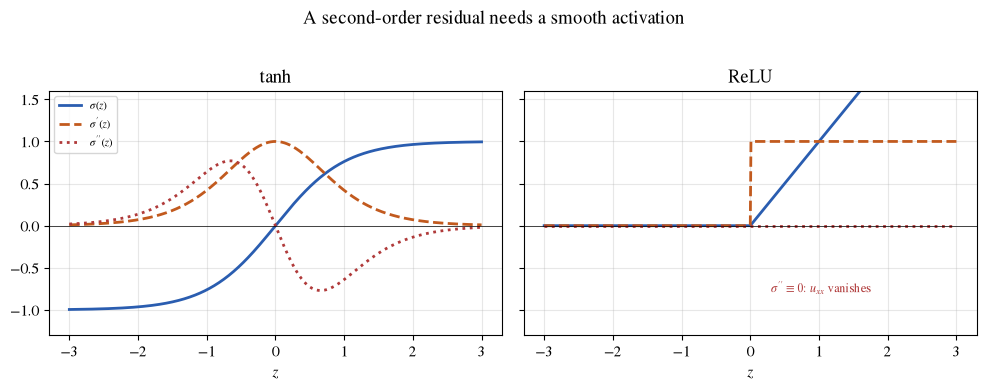

In [12]:
def plot_ad_activations():
    zz = zs.detach().numpy()
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
    for a_, (vals, name) in zip(ax, [(act_tanh, 'tanh'), (act_relu, 'ReLU')]):
        a_.plot(zz, vals[0], color='C0', lw=2, label=r'$\sigma(z)$')
        a_.plot(zz, vals[1], color='C1', lw=2, ls='--', label=r"$\sigma'(z)$")
        a_.plot(zz, vals[2], color='C3', lw=2, ls=':', label=r"$\sigma''(z)$")
        a_.axhline(0, color=fg(), lw=0.5)
        a_.set(xlabel='$z$', title=name)
    ax[0].set_ylim(-1.3, 1.6)
    ax[0].legend(loc='upper left', fontsize=8)
    ax[1].annotate(r"$\sigma''\equiv 0$: $u_{xx}$ vanishes", xy=(0.3, -0.8), color='C3', fontsize=9)
    fig.suptitle('A second-order residual needs a smooth activation', y=1.02)
    plt.tight_layout()

save_dual(plot_ad_activations, 'pinn_ad_activations', FIG)
plt.show()

**What a ReLU heat PINN actually solves.** For
$\hat u=\sum_j v_j\,\mathrm{ReLU}(w_jx+\dots)$ the chain rule gives

$$\hat u_x=\sum_j v_jw_j\,H(\cdot),\qquad \hat u_{xx}=\sum_j v_jw_j^2\,\delta(\cdot)=0
  \ \text{almost everywhere},$$

with $H$ the step function. At every collocation point the heat residual
collapses to $r=\hat u_t-\alpha\cdot0=\hat u_t$, so the loss asks for
$u_t=0$ plus the initial and boundary conditions. Its solution is the initial
profile frozen in time: $u(x,t)=\sin\pi x$. We train the same heat PINN with
both activations and check.

In [13]:
def train_heat_pinn(act, steps=RELU_STEPS, width=RELU_WIDTH):
    torch.manual_seed(SEED)
    net_ = torch.nn.Sequential(torch.nn.Linear(2, width), act(), torch.nn.Linear(width, width),
                               act(), torch.nn.Linear(width, 1))
    opt = torch.optim.Adam(net_.parameters(), lr=2e-3)
    for _ in range(steps):
        xc = torch.rand(1000, 1, requires_grad=True); tc = torch.rand(1000, 1, requires_grad=True)
        uc = net_(torch.cat([xc, tc], 1))
        (ut,) = torch.autograd.grad(uc, tc, torch.ones_like(uc), create_graph=True)
        (ux,) = torch.autograd.grad(uc, xc, torch.ones_like(uc), create_graph=True)
        (uxx,) = torch.autograd.grad(ux, xc, torch.ones_like(ux), create_graph=True, allow_unused=True)
        uxx = torch.zeros_like(xc) if uxx is None else uxx      # ReLU: u_x does not depend on x
        xi = torch.rand(200, 1); tb = torch.rand(200, 1)
        Li = ((net_(torch.cat([xi, torch.zeros_like(xi)], 1)) - torch.sin(np.pi * xi))**2).mean()
        Lb = (net_(torch.cat([torch.zeros_like(tb), tb], 1))**2).mean() + \
             (net_(torch.cat([torch.ones_like(tb), tb], 1))**2).mean()
        L = ((ut - ALPHA * uxx)**2).mean() + 10 * Li + 10 * Lb
        opt.zero_grad(); L.backward(); opt.step()
    return net_

xs_ = np.linspace(0, 1, 101)
t_show = [0.0, 0.5, 1.0]
heat_exact = lambda x, t: np.exp(-ALPHA * np.pi**2 * t) * np.sin(np.pi * x)
profiles = {}
for name, act in [('tanh', torch.nn.Tanh), ('ReLU', torch.nn.ReLU)]:
    net_ = train_heat_pinn(act)
    with torch.no_grad():
        profiles[name] = [net_(torch.tensor(np.c_[xs_, np.full_like(xs_, tt)])).numpy().ravel() for tt in t_show]
for name in profiles:
    err_T = np.abs(profiles[name][-1] - heat_exact(xs_, 1.0)).max()
    frozen = np.abs(profiles[name][-1] - profiles[name][0]).max()
    print(f'{name:5s}: max error at t=1 {err_T:.3f};  max change u(x,1)-u(x,0) {frozen:.3f}'
          f'  (exact change {1 - np.exp(-ALPHA * np.pi**2):.3f})')

tanh : max error at t=1 0.007;  max change u(x,1)-u(x,0) 0.628  (exact change 0.627)
ReLU : max error at t=1 0.636;  max change u(x,1)-u(x,0) 0.016  (exact change 0.627)


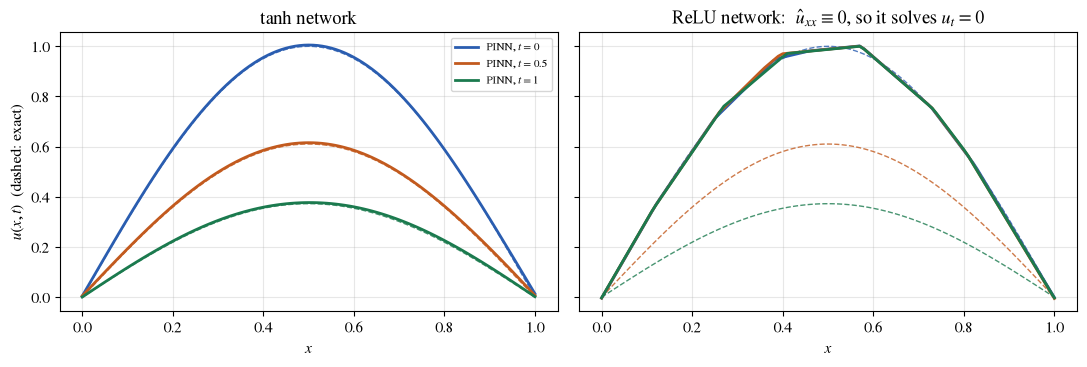

In [14]:
def plot_ad_relu_heat():
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    for ax, name in zip(axes, ['tanh', 'ReLU']):
        for k, tt in enumerate(t_show):
            ax.plot(xs_, profiles[name][k], color=f'C{k}', lw=2, label=f'PINN, $t={tt:g}$')
            ax.plot(xs_, heat_exact(xs_, tt), '--', color=f'C{k}', lw=1, alpha=0.8)
        ax.set(xlabel='$x$', title=f'{name} network' + ('' if name == 'tanh' else
               r':  $\hat u_{xx}\equiv0$, so it solves $u_t=0$'))
    axes[0].set_ylabel('$u(x,t)$  (dashed: exact)')
    axes[0].legend(fontsize=8)
    plt.tight_layout()

save_dual(plot_ad_relu_heat, 'pinn_ad_relu_heat', FIG)
plt.show()

In [15]:
relu_change = np.abs(profiles['ReLU'][-1] - profiles['ReLU'][0]).max()
tanh_err = np.abs(profiles['tanh'][-1] - heat_exact(xs_, 1.0)).max()
assert relu_change < 0.1, "the ReLU PINN leaves the initial profile (almost) unchanged"
assert tanh_err < 0.05, "the tanh PINN follows the decaying exact solution"

## 7. Vector outputs and the Laplacian — two common bugs

**Vector outputs.** With an output $(u,v)$, `grad(out, x, ones_like(out))`
returns $\partial(u+v)/\partial x$ — the *sum* over components, not either
derivative. Select the component first.

**Laplacian.** For $\boldsymbol x\in\mathbb{R}^d$,
$\Delta u=\sum_i\partial^2u/\partial x_i^2$ — the trace of the Hessian. A
vector–Jacobian product does not hand you that trace. Applying the
"all-ones" trick twice to the full input vector returns the **row sums of
the Hessian**, $\sum_j\partial^2u/\partial x_i\partial x_j$, which includes
the cross terms. The correct recipe takes one more backward pass per
coordinate and keeps only the diagonal entry — so its cost grows with $d$.

Test function with a known Laplacian:
$u=e^{-\|\boldsymbol x\|^2}$, $\Delta u=(4\|\boldsymbol x\|^2-2d)\,e^{-\|\boldsymbol x\|^2}$.

In [16]:
# vector output: pick the component before differentiating
xv = torch.rand(5, 1, requires_grad=True)
out = torch.cat([torch.sin(xv), xv**3], 1)                  # (u, v) = (sin x, x^3)
(wrong,) = torch.autograd.grad(out, xv, torch.ones_like(out), retain_graph=True)
(du_dx,) = torch.autograd.grad(out[:, 0:1], xv, torch.ones_like(xv), retain_graph=True)
(dv_dx,) = torch.autograd.grad(out[:, 1:2], xv, torch.ones_like(xv))
assert torch.allclose(du_dx, torch.cos(xv)) and torch.allclose(dv_dx, 3 * xv**2)
assert torch.allclose(wrong, torch.cos(xv) + 3 * xv**2)
print('ones-trick on a 2-output net returns du/dx + dv/dx, not either one')

# Laplacian in D_LAP dimensions
X = (torch.rand(N_COL, D_LAP) - 0.5).requires_grad_(True)
uL = torch.exp(-(X**2).sum(1, keepdim=True))
lap_exact = (4 * (X**2).sum(1, keepdim=True) - 2 * D_LAP) * uL

(g,) = torch.autograd.grad(uL, X, torch.ones_like(uL), create_graph=True)   # (N, d) gradient
lap = torch.zeros_like(uL)
for i in range(D_LAP):                                       # one backward pass per coordinate
    (gi,) = torch.autograd.grad(g[:, i:i+1], X, torch.ones_like(uL), create_graph=True)
    lap = lap + gi[:, i:i+1]                                 # keep only d2u/dxi2
(row_sums,) = torch.autograd.grad(g, X, torch.ones_like(g))  # the bug: Hessian row sums
naive = row_sums.sum(1, keepdim=True)
err_lap = (lap - lap_exact).abs().max().item()
err_naive = (naive - lap_exact).abs().max().item()
print(f'correct Laplacian: max error {err_lap:.1e}')
print(f'"grad twice" on the vector input: max error {err_naive:.1e}  (includes cross terms)')
assert err_lap < 1e-13 and err_naive > 1e-2

ones-trick on a 2-output net returns du/dx + dv/dx, not either one
correct Laplacian: max error 8.9e-16
"grad twice" on the vector input: max error 2.5e+00  (includes cross terms)


**When the all-ones shortcut breaks.** If samples interact inside the model,
the vector–Jacobian product mixes them. A toy layer that subtracts the batch
mean (as batch normalization does) is enough:

In [17]:
xb = torch.rand(6, 1, requires_grad=True)
ub = torch.sin(xb - xb.mean())                      # samples now interact
(per_sample_wrong,) = torch.autograd.grad(ub, xb, torch.ones_like(ub))
# true per-sample derivative: d u_i / d x_i = cos(x_i - mean) * (1 - 1/N)
true_diag = torch.cos(xb - xb.mean()).detach() * (1 - 1 / xb.shape[0])
print('max |ones-trick - true per-sample derivative| =',
      f'{(per_sample_wrong - true_diag).abs().max().item():.2e}')
assert (per_sample_wrong - true_diag).abs().max().item() > 1e-3

max |ones-trick - true per-sample derivative| = 8.09e-01


## 8. Exercise — then meet the helper

The wake model in `pinn_wind_pde` is $U\,\partial_x d=\nu_t\,\partial_{yy}d$.
Write its residual with raw `torch.autograd.grad` calls and check it on the
manufactured solution
$d(x,y)=(4\pi Dx)^{-1/2}e^{-y^2/(4Dx)}$, $D=\nu_t/U$, which satisfies it
exactly. A reference solution follows; try it yourself first.

In [18]:
U_, NU_T = 8.0, 0.5
xw = (1 + 5 * torch.rand(N_COL, 1)).requires_grad_(True)
yw = (6 * torch.rand(N_COL, 1) - 3).requires_grad_(True)

def wake_residual(dfun, x, y):
    # --- reference solution ---
    d = dfun(x, y)
    (d_x,) = torch.autograd.grad(d, x, torch.ones_like(d), create_graph=True)
    (d_y,) = torch.autograd.grad(d, y, torch.ones_like(d), create_graph=True)
    (d_yy,) = torch.autograd.grad(d_y, y, torch.ones_like(d_y), create_graph=True)
    return U_ * d_x - NU_T * d_yy

Dw = NU_T / U_
wake_exact = lambda x, y: torch.exp(-y**2 / (4 * Dw * x)) / torch.sqrt(4 * np.pi * Dw * x)
r_w = wake_residual(wake_exact, xw, yw)
print(f'max |wake residual of the exact solution| = {r_w.abs().max().item():.1e}')
assert r_w.abs().max().item() < 1e-12

max |wake residual of the exact solution| = 8.9e-16


From here on the PINN notebooks use `pyutils.pinn_core.grad`. It is exactly
the call you just wrote:

```python
def grad(y, x):
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]
```

so it inherits both caveats from section 7: it differentiates the *sum* of
the outputs, and applied twice to a vector input it does not give a
Laplacian.

In [19]:
from pyutils.pinn_core import grad
u = net(torch.cat([x, t], dim=1))
(u_x_raw,) = torch.autograd.grad(u, x, torch.ones_like(u), create_graph=True)
assert torch.equal(grad(u, x), u_x_raw)
print('pc.grad(u, x) is identical to the raw call')

pc.grad(u, x) is identical to the raw call


## Summary

* AD applies the chain rule to the operations the network performs; its
  derivatives are exact up to rounding, with no step size to tune.
* A PINN uses AD twice: **input** derivatives build the residual, the
  **parameter** gradient of the loss trains the network. `create_graph=True`
  connects the two.
* The all-ones `grad_outputs` trick gives per-sample derivatives only when
  samples do not interact, and it sums vector outputs.
* A Laplacian needs one extra backward pass per coordinate; its cost grows
  with dimension.
* A strong-form second-order residual needs a smooth activation; ReLU's
  $u_{xx}$ is identically zero.

In [20]:
if AT_DEFAULTS:
    # numbers quoted on the slides and in the chapter
    assert 1e-11 < err_fd1.min() < 1e-9, f"best FD first-derivative error {err_fd1.min():.1e}"
    assert 1e-9 < err_fd2.min() < 1e-6, f"best FD second-derivative error {err_fd2.min():.1e}"
    print(f'slide numbers: best FD error f\' {err_fd1.min():.0e}, f\'\' {err_fd2.min():.0e}; AD {max(err_ad1, err_ad2):.0e}')
else:
    print('regression check skipped (parameters differ from the slide defaults)')

slide numbers: best FD error f' 2e-11, f'' 1e-08; AD 4e-16
